# BioCLIP vs CLIP: zero-shot plant disease recognition on DPD-Small

This notebook tests two image-text models on our test sets **without any training** ("zero-shot"),
and compares them with our trained baselines.

- **CLIP** (OpenAI, 2021): learned from ~400M general internet images and their captions.
- **BioCLIP** (Imageomics, CVPR 2024): CLIP trained further on ~10M images of living things, labelled with their species names.

The question: *does a model that already knows plants help on our task, before we train anything?*

Runs on **Google Colab** (Runtime > Change runtime type > T4 GPU) or **locally** inside the repo. About 10 minutes the first time
(model download + two passes over the test images); later runs reuse the saved results.

## 1. What the two models are

| | CLIP | BioCLIP |
|---|---|---|
| Architecture | ViT-B/16 image encoder + text encoder | Same (it starts from CLIP's weights) |
| Training images | ~400M general web images | ~10M images of organisms (TreeOfLife-10M) |
| Training text | Web captions ("my dog at the beach") | Taxonomic + common names ("Plantae ... Solanaceae *Solanum lycopersicum*", "tomato") |
| Good at | Telling general things apart | Telling similar species apart |

Both map an image and a sentence into the same space. **Zero-shot classification** = write one sentence per class,
and give the image the class whose sentence is closest. Because a sentence can describe *any* crop-disease pair,
pairs never seen together in training (our *unseen* test set) are scored exactly like seen ones.

## 2. Settings

In [1]:
# ===== Edit these (only used on Colab) =====
DRIVE_ROOT  = "/content/drive/MyDrive/AML_Group_Project"   # team folder (a shortcut in your My Drive)
DATA_DIR    = f"{DRIVE_ROOT}/Dataset"                     # 3 CSVs + DPD_Small.7z
REPO_URL    = "https://github.com/Daryl711/COS30028_ML_Project.git"
BRANCH      = "main"
# ===== Edit these (everywhere) =====
FORCE_RERUN = False   # True = evaluate again even if results already exist
# ====================================

# Zero-shot models: open_clip name, weights tag, results folder
ZERO_SHOT = {
    "BioCLIP": {"model": "hf-hub:imageomics/bioclip", "pretrained": None, "out": "outputs/zeroshot_bioclip/eval"},
    "CLIP":    {"model": "ViT-B-16-quickgelu", "pretrained": "openai", "out": "outputs/zeroshot_clip/eval"},
}
# Trained baselines to compare against (shown if their results exist)
TRAINED = {
    "EffB0 (trained)":  "outputs/multitask_effb0/eval/metrics.json",
    "EffB3 (trained)":  "outputs/multitask_effb3/eval/metrics.json",
    "DINOv2 (trained)": "outputs/multitask_dinov2/eval/metrics.json",
}
# One fixed colour per model, used in every chart
COLORS = {"BioCLIP": "#2a78d6", "CLIP": "#eb6834", "EffB0 (trained)": "#1baf7a",
          "EffB3 (trained)": "#eda100", "DINOv2 (trained)": "#e87ba4"}

## 3. Get the code and the data

In [2]:
import os
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
CSVS = ["DPD_Small_train.csv", "DPD_Small_test_seen.csv", "DPD_Small_test_unseen.csv"]

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    assert os.path.isdir(DATA_DIR), f"{DATA_DIR} not found. Add the team folder to your My Drive (Add shortcut)."
    REPO = "/content/proj"
    if os.path.isdir(REPO):
        # Cloned earlier in this runtime. Restarting the session keeps /content, so pull to get the newest code.
        r = subprocess.run(["git", "-C", REPO, "pull", "-q", "--ff-only", "origin", BRANCH], capture_output=True, text=True)
        if r.returncode:
            raise RuntimeError(f"git pull failed. Delete the old copy with !rm -rf {REPO} and run this cell again:\n" + r.stderr)
    else:
        url, token = REPO_URL, None
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
            url = REPO_URL.replace("https://", f"https://{token}@")
        except Exception:
            pass  # no token: fine for a public repo
        r = subprocess.run(["git", "clone", "-q", "--branch", BRANCH, url, REPO], capture_output=True, text=True)
        if r.returncode:
            err = r.stderr.replace(token, "***") if token else r.stderr
            raise RuntimeError("git clone failed. If the repo is private, add a GITHUB_TOKEN in the Secrets panel:\n" + err)
    os.chdir(REPO)
else:
    # Local: walk up from this notebook's folder to the repo root.
    root = os.path.abspath(os.getcwd())
    while not os.path.isdir(os.path.join(root, "baseline", "ZeroShot")):
        parent = os.path.dirname(root)
        if parent == root:
            raise FileNotFoundError("Open this notebook from inside the project repo.")
        root = parent
    os.chdir(root)

print("Working in", os.getcwd())

Working in C:\COS30082_ML_Project


In [3]:
import glob
import shutil
import zipfile

IMG_DIR = "dataset/DPD_Small_dataset"
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

if IN_COLAB:
    # Copy the CSVs and unpack the images to Colab's local disk (reading from Drive is slow).
    os.makedirs("dataset", exist_ok=True)
    for name in CSVS:
        shutil.copy(f"{DATA_DIR}/{name}", f"dataset/{name}")
    if os.path.isdir(IMG_DIR) and os.listdir(IMG_DIR):
        print("Images already unpacked.")
    else:
        archive = f"{DATA_DIR}/DPD_Small.7z"
        if not os.path.isfile(archive):
            found = sorted(glob.glob(f"{DATA_DIR}/*.7z") + glob.glob(f"{DATA_DIR}/*.zip"))
            assert found, f"No .7z or .zip image archive in {DATA_DIR}"
            archive = found[0]
        local = "/content/" + os.path.basename(archive)
        print("Copying", archive)
        shutil.copy(archive, local)
        shutil.rmtree("/content/unpacked", ignore_errors=True)
        print("Unpacking...")
        if local.endswith(".zip"):
            with zipfile.ZipFile(local) as z:
                z.extractall("/content/unpacked")
        elif shutil.which("7z"):
            !7z x -y -o/content/unpacked "{local}" > /dev/null
        else:
            !pip -q install py7zr
            import py7zr
            with py7zr.SevenZipFile(local) as z:
                z.extractall("/content/unpacked")
        # Use the folder that holds the images, wherever it sits inside the archive.
        counts = {r: sum(f.lower().endswith(IMG_EXT) for f in fs) for r, _, fs in os.walk("/content/unpacked")}
        shutil.rmtree(IMG_DIR, ignore_errors=True)
        shutil.move(max(counts, key=counts.get), IMG_DIR)
        os.remove(local)

missing = [n for n in CSVS if not os.path.isfile(f"dataset/{n}")]
assert not missing and os.path.isdir(IMG_DIR), f"Put the CSVs and {IMG_DIR} in dataset/ (missing: {missing or IMG_DIR})"
print("Images:", len(os.listdir(IMG_DIR)))

Images: 11448


In [4]:
%pip install -q open_clip_torch

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from PIL import Image

sys.path.insert(0, "baseline/ZeroShot/BioCLIP")
import zeroshot as zs
from dataset import audit, build_label_space, read_split

%matplotlib inline

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU (works, but slow)")

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlecolor": "#0b0b0b", "axes.titleweight": "bold", "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True, "legend.frameon": False,
})


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


Device: NVIDIA GeForce RTX 3060 Laptop GPU


## 4. The dataset

DPD-Small labels each image with a **crop** and a **disease**. The *seen* test set uses crop-disease pairs that
appear in training; the *unseen* test set uses pairs that never appear together in training
(each crop and each disease on its own does). Models choose among **all** seen + unseen pairs.

In [5]:
train_df = read_split(f"dataset/{CSVS[0]}")
seen_df = read_split(f"dataset/{CSVS[1]}")
unseen_df = read_split(f"dataset/{CSVS[2]}")
ls = build_label_space(train_df, seen_df, unseen_df)
audit(train_df, seen_df, unseen_df, ls)

unseen_counts = unseen_df.groupby(["crop_name", "disease_name"]).size().rename("test images")
print("\nThe unseen pairs:")
display(unseen_counts.reset_index())

[data] train=8000 test_seen=2000 test_unseen=1448
[data] crops=55 diseases=175 seen pairs=323 unseen pairs=10
[data] every unseen crop and disease appears in train -> compositional zero-shot setting
[data] images per seen pair: min=1 median=7 max=544

The unseen pairs:


,crop_name,disease_name,test images
0,cherry,aphis_spp,72
1,corn,brown_spot,35
2,cotton,bacterial_blight,125
3,cucumber,downy_mildew,32
4,cucumber,powdery_mildew,37
5,grape,black_rot,271
6,mango,anthracnose,95
7,pepper_bell,bacterial_spot,220
8,sugarcane,rust,89
9,tomato,early_blight,472


## 5. What the models read: the prompts

Every crop, disease and pair becomes three sentences; the class embedding is their average.
Underscores become spaces, and a few dataset names are fixed so they read as English (e.g. `paddy` -> rice, `segatoka` -> sigatoka).

In [6]:
prompts = zs.build_prompts(ls)
idx = ls.pair_index()
examples = {
    "seen pair": ls.pairs[0],
    "unseen pair": ls.unseen_pairs[0],
    "healthy pair": next(p for p in ls.pairs if ls.disease_names[p[1]] == "healthy"),
}
for kind, pair in examples.items():
    print(f"{kind}: {ls.pair_name(idx[pair])}")
    for s in prompts["pair"][idx[pair]]:
        print("   ", s)

seen pair: apple | alternaria_blotch
    a photo of an apple leaf with alternaria blotch.
    a photo of an apple plant with alternaria blotch.
    a close-up photo of alternaria blotch on an apple leaf.
unseen pair: pepper_bell | bacterial_spot
    a photo of a bell pepper leaf with bacterial spot.
    a photo of a bell pepper plant with bacterial spot.
    a close-up photo of bacterial spot on a bell pepper leaf.
healthy pair: apple | healthy
    a photo of a healthy apple leaf.
    a photo of a healthy apple plant.
    a close-up photo of a healthy apple leaf.


## 6. Run the zero-shot evaluation

Runs `baseline/ZeroShot/BioCLIP/zeroshot.py` once per model. It reports the same numbers as our trained
baselines' `evaluate.py` and saves them under `outputs/`. Skipped when results already exist.

In [7]:
def run_zero_shot(name, cfg):
    metrics = f"{cfg['out']}/metrics.json"
    # predictions.csv is not committed (see .gitignore), so a fresh clone runs the evaluation once.
    if os.path.isfile(metrics) and os.path.isfile(f"{cfg['out']}/predictions.csv") and not FORCE_RERUN:
        with open(metrics) as f:
            if "calibration_curve" in json.load(f):
                print(f"{name}: results already in {cfg['out']}, skipping. Set FORCE_RERUN = True to run again.")
                return
    cmd = f'"{sys.executable}" baseline/ZeroShot/BioCLIP/zeroshot.py --model {cfg["model"]} --out {cfg["out"]} --batch_size 64'
    if cfg["pretrained"]:
        cmd += f" --pretrained {cfg['pretrained']}"
    print("$", cmd)
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    lines = [l for l in r.stdout.splitlines() if l.strip()]
    print("\n".join(lines[-16:]))
    if r.returncode:
        raise RuntimeError(r.stderr[-3000:])


for name, cfg in ZERO_SHOT.items():
    run_zero_shot(name, cfg)

BioCLIP: results already in outputs/zeroshot_bioclip/eval, skipping. Set FORCE_RERUN = True to run again.
CLIP: results already in outputs/zeroshot_clip/eval, skipping. Set FORCE_RERUN = True to run again.


## 7. Results

**Pair** = the full crop + disease prediction. **HM** = harmonic mean of seen and unseen pair accuracy
(high only if both are high). Models favour seen pairs, so the standard fix is to add a bonus to unseen-pair
scores; **best HM** is the HM at the best bonus, and **AUC** is the area under the seen-vs-unseen curve over all bonuses.

In [8]:
def load(path):
    with open(path) as f:
        return json.load(f)


results = {name: load(f"{cfg['out']}/metrics.json") for name, cfg in ZERO_SHOT.items()}
results.update({name: load(path) for name, path in TRAINED.items() if os.path.isfile(path)})

table = pd.DataFrame({
    name: {
        "seen crop": m["seen"]["crop"]["top1"],
        "seen disease": m["seen"]["disease"]["top1"],
        "seen pair": m["seen"]["composition"]["top1"],
        "unseen crop": m["unseen"]["crop"]["top1"],
        "unseen disease": m["unseen"]["disease"]["top1"],
        "unseen pair": m["unseen"]["composition"]["top1"],
        "HM": m["harmonic_mean"]["top1"],
        "best HM": m["calibrated"]["best_hm"],
        "AUC": m["calibrated"]["auc"],
    }
    for name, m in results.items()
}).T
print("Top-1 accuracy")
display(table.style.format("{:.3f}").background_gradient(cmap="Blues", axis=0, vmin=0, vmax=1))

Top-1 accuracy


,seen crop,seen disease,seen pair,unseen crop,unseen disease,unseen pair,HM,best HM,AUC
BioCLIP,0.349,0.028,0.061,0.325,0.257,0.274,0.100,0.105,0.036
CLIP,0.340,0.021,0.071,0.248,0.024,0.033,0.045,0.097,0.027
EffB0 (trained),0.900,0.694,0.679,0.669,0.108,0.049,0.091,0.607,0.471


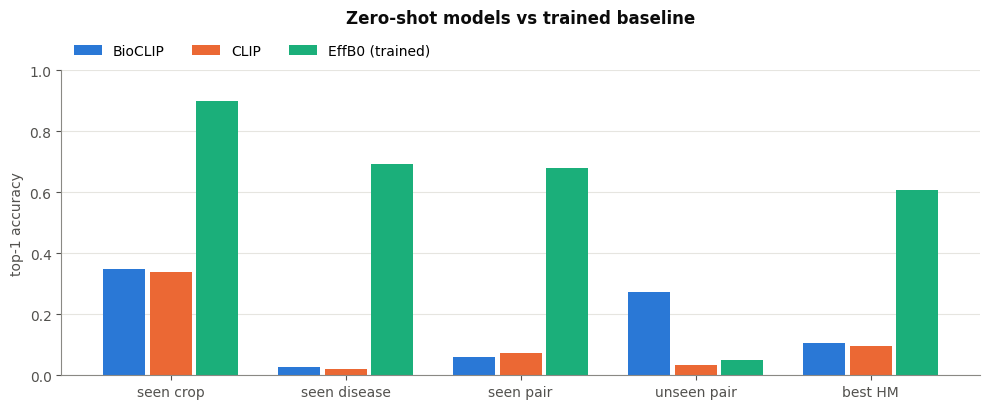

In [9]:
cols = ["seen crop", "seen disease", "seen pair", "unseen pair", "best HM"]
names = list(table.index)
x = np.arange(len(cols))
w = 0.8 / len(names)

fig, ax = plt.subplots(figsize=(10, 4.2))
for i, name in enumerate(names):
    ax.bar(x + (i - (len(names) - 1) / 2) * w, table.loc[name, cols], width=w * 0.9,
           color=COLORS.get(name, "#8a8984"), label=name)
ax.set_xticks(x, cols)
ax.set_ylim(0, 1)
ax.set_ylabel("top-1 accuracy")
ax.set_title("Zero-shot models vs trained baseline", pad=34)
ax.legend(ncol=len(names), loc="lower left", bbox_to_anchor=(0, 1.0))
plt.tight_layout()
plt.show()

### The seen-unseen trade-off

Each curve shows what happens as the bonus for unseen pairs grows: unseen accuracy goes up, seen accuracy goes down.
A model is better the closer its curve gets to the top-right corner. The dots are the trained baselines' best-HM points.
The right panel zooms in on the zero-shot curves, which sit squashed against the left edge at full scale.

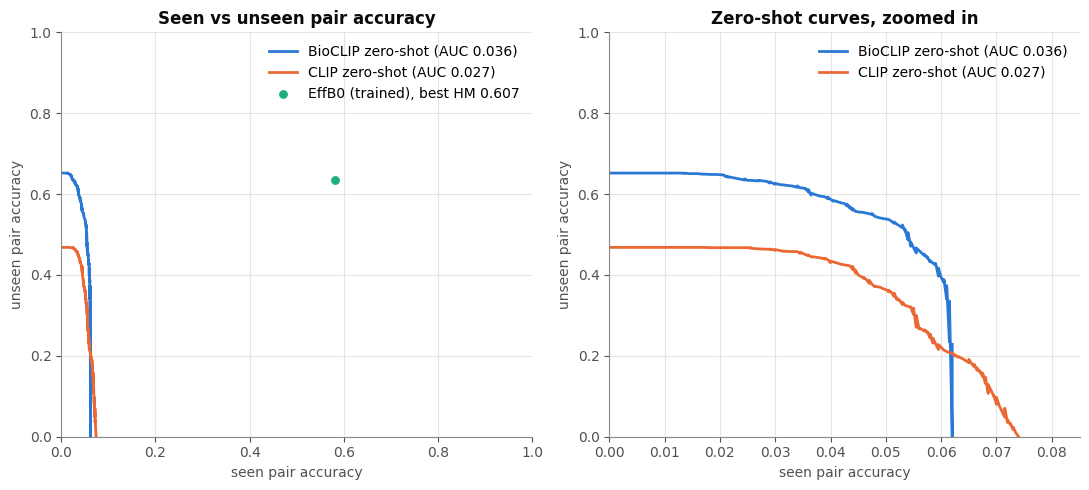

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, zoom in zip(axes, (False, True)):
    for name in ZERO_SHOT:
        c = results[name]["calibration_curve"]
        ax.plot(c["seen_acc"], c["unseen_acc"], lw=2, color=COLORS[name],
                label=f"{name} zero-shot (AUC {results[name]['calibrated']['auc']:.3f})")
    if not zoom:
        for name in TRAINED:
            if name in results:
                cal = results[name]["calibrated"]
                ax.scatter(cal["seen_at_best"], cal["unseen_at_best"], s=70, color=COLORS[name],
                           edgecolor="white", linewidth=2, zorder=3, label=f"{name}, best HM {cal['best_hm']:.3f}")
    xmax = 1 if not zoom else 1.15 * max(max(results[n]["calibration_curve"]["seen_acc"]) for n in ZERO_SHOT)
    ax.set(xlim=(0, xmax), ylim=(0, 1), xlabel="seen pair accuracy", ylabel="unseen pair accuracy")
    ax.grid(True, axis="both")
    ax.set_title("Zero-shot curves, zoomed in" if zoom else "Seen vs unseen pair accuracy")
    ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

## 8. Example predictions

Random test images with each model's top guess (✓ = correct pair).

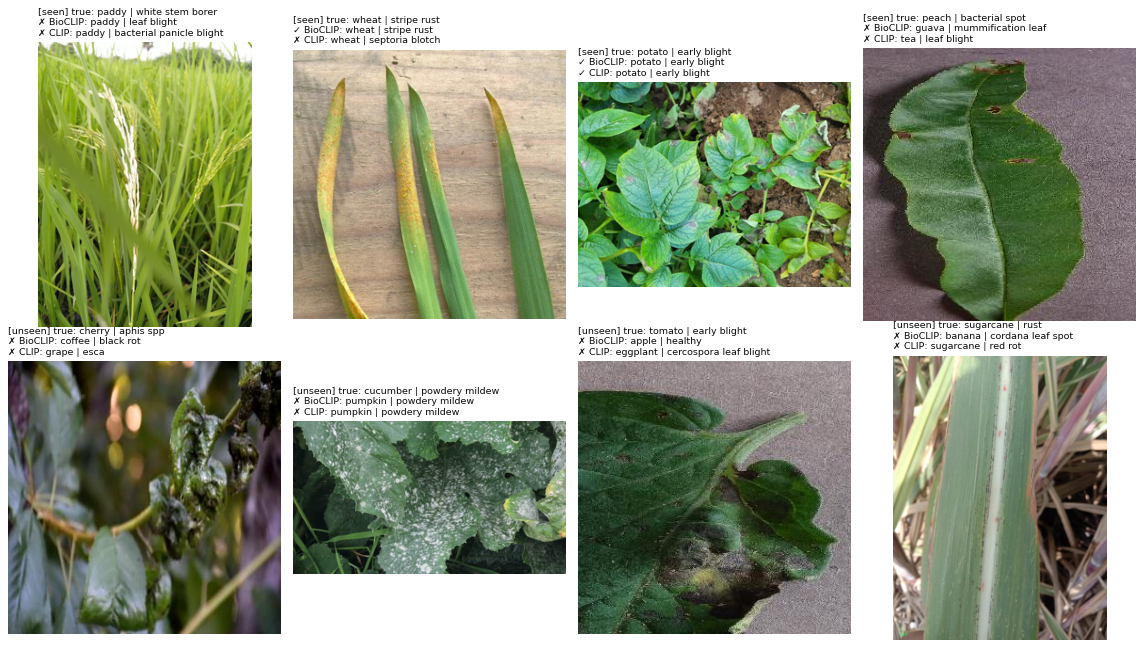

In [11]:
N_PER_SPLIT = 4
SEED = 0

preds = {name: pd.read_csv(f"{cfg['out']}/predictions.csv") for name, cfg in ZERO_SHOT.items()}
base = preds["BioCLIP"]
sample = pd.concat([base[base.split == s].sample(N_PER_SPLIT, random_state=SEED) for s in ("seen", "unseen")])


def short(pair):
    return pair.replace(" | ", "\n").replace("_", " ")


fig, axes = plt.subplots(2, N_PER_SPLIT, figsize=(3.6 * N_PER_SPLIT, 8.2), dpi=80)
for ax, (i, row) in zip(axes.flat, sample.iterrows()):
    thumb = Image.open(f"{IMG_DIR}/{row.image}").convert("RGB")
    thumb.thumbnail((300, 300))
    ax.imshow(thumb)
    ax.axis("off")
    lines = [f"[{row.split}] true: {row.true.replace('_', ' ')}"]
    for name, df in preds.items():
        guess = df.loc[i, "pred_1"]
        lines.append(f"{'✓' if guess == row.true else '✗'} {name}: {guess.replace('_', ' ')}")
    ax.set_title("\n".join(lines), fontsize=8.5, loc="left", fontweight="normal")
plt.tight_layout()
plt.show()

## 9. Try a single image

Change `IMAGE` to any file in `dataset/DPD_Small_dataset/` (or a path to your own photo) to see each model's top 5 pairs.
The default is the first unseen test image that BioCLIP gets right; section 8 shows typical hits and misses.

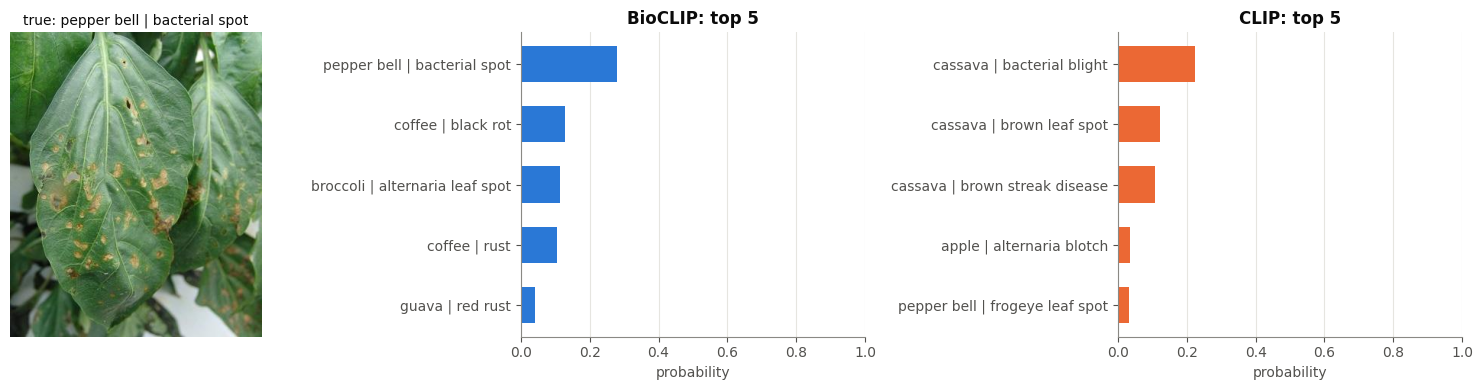

In [12]:
import open_clip

hits = preds["BioCLIP"].query("split == 'unseen' and pred_1 == true")
IMAGE = hits["image"].iloc[0] if len(hits) else unseen_df["image"].iloc[0]   # change me
TOP_K = 5

if "loaded" not in globals():
    loaded = {}
    for name, cfg in ZERO_SHOT.items():
        model, _, preprocess = open_clip.create_model_and_transforms(cfg["model"], pretrained=cfg["pretrained"])
        model = model.to(DEVICE).eval()
        text = zs.encode_texts(model, open_clip.get_tokenizer(cfg["model"]), prompts["pair"], DEVICE)
        loaded[name] = (model, preprocess, text)

path = IMAGE if os.path.isfile(IMAGE) else f"{IMG_DIR}/{IMAGE}"
img = Image.open(path).convert("RGB")
true = unseen_df.loc[unseen_df.image == IMAGE]
true = true if len(true) else seen_df.loc[seen_df.image == IMAGE]

fig, axes = plt.subplots(1, 1 + len(loaded), figsize=(5 + 5 * len(loaded), 4),
                         gridspec_kw={"width_ratios": [1] + [1.3] * len(loaded)})
axes[0].imshow(img)
axes[0].axis("off")
axes[0].set_title("true: " + (f"{true.crop_name.iloc[0]} | {true.disease_name.iloc[0]}".replace("_", " ")
                                if len(true) else "unknown"), fontsize=10, fontweight="normal")
for ax, (name, (model, preprocess, text)) in zip(axes[1:], loaded.items()):
    with torch.no_grad():
        f = model.encode_image(preprocess(img).unsqueeze(0).to(DEVICE)).float()
        f = f / f.norm(dim=-1, keepdim=True)
        prob = (model.logit_scale.exp() * f @ text.T).softmax(-1)[0].cpu().numpy()
    top = np.argsort(-prob)[:TOP_K][::-1]
    ax.barh([short(ls.pair_name(i)).replace("\n", " | ") for i in top], prob[top], color=COLORS[name], height=0.6)
    ax.set_xlim(0, 1)
    ax.grid(True, axis="x")
    ax.grid(False, axis="y")
    ax.set_xlabel("probability")
    ax.set_title(f"{name}: top {TOP_K}")
plt.tight_layout()
plt.show()

## 10. Takeaways

- **BioCLIP's clear win over CLIP is on the unseen pairs**: about 27% vs 3% pair accuracy, and HM 0.10 vs 0.05.
  It also recognises unseen crops better (32% vs 25%).
- **On the seen pairs the two are level** (6% vs 7%, CLIP slightly ahead), and seen crop accuracy is about the same (35% vs 34%).
- **Diseases are the weak point for both** (under 3% on seen diseases, out of 175). Both were trained on species names or
  general captions, not disease names, and mostly on whole organisms rather than close-ups of diseased leaves.
- **Zero-shot alone is far behind a trained model.** After the unseen-pair bonus, trained EfficientNet-B0 reaches a best HM of about 0.61;
  zero-shot BioCLIP about 0.10.
- **Next step:** fine-tune BioCLIP's image encoder on DPD-Small as a third backbone (same size as CLIP, but starts with plant knowledge),
  and try keeping its text encoder so unseen pairs can still be scored from their names.
- Caveat: the unseen test set has only 10 pairs, and half its images are tomato early blight and grape black rot,
  two very well-documented diseases. BioCLIP's unseen advantage rests on those few pairs.